# Multi-Armed Bandits and Thompson Sampling

**What you'll learn**

- Regret as the objective that separates *optimization* from *inference*, and why a fixed
  A/B/n test pays its full exploration cost for the entire test — linear regret by design.
- Working implementations of $\varepsilon$-greedy, UCB1 (plus the variance-aware tuned
  variant), and Beta-Bernoulli Thompson sampling, raced on realistic CTR arms over
  hundreds of seeded replications: cumulative regret curves and how each policy's
  traffic allocation evolves.
- Thompson sampling as *posterior sampling*: the same Beta-Binomial engine as
  [01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb), turned into an
  allocation rule — pull each arm with the posterior probability that it is the best.
- What production does to the textbook algorithm: batched/nightly updates (randomization
  saves Thompson sampling, deterministic UCB degrades badly) and non-stationary arms
  (a drifting CTR defeats a stale posterior; sliding windows and discounting fix it).
- Why bandit arm means are **biased** estimates of arm quality — adaptively collected
  data systematically underestimates — and what that implies for reading "lift" off a
  bandit dashboard. A bandit-vs-A/B decision framework.
- Contextual bandits: LinUCB in ~40 lines, beating any context-free policy when the best
  arm depends on who is looking.

**Why it matters in interviews**

- "When would you use a bandit instead of an A/B test?" is a standard senior
  experimentation question; strong answers talk about regret vs inference, arm lifetime,
  and switching costs — not just "bandits are faster".
- System-design prompts like "design a headline/creative optimization service" are really
  bandit questions in disguise: batching, delayed rewards, non-stationarity, cold-start
  priors, and holdouts are where senior candidates differentiate.
- "Can you read the lift off the bandit's arm means?" probes whether you understand
  adaptive sampling bias — most candidates don't.
- Thompson sampling is the de facto industry default (ad systems, recommendations,
  in-house experimentation platforms); you should be able to derive it, code it, and
  explain *why* its exploration is self-tuning.

Everything is simulated so ground truth is known and every claim is checkable. The
frequentist A/B pipeline this chapter pushes against is
[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb);
the posterior machinery is built in
[01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)          # global RNG for small one-off draws

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)


def child_rng(*key):
    """A dedicated, reproducible generator for each big simulation.

    Deriving generators from (SEED, key) keeps every experiment deterministic even
    though they run in different cells."""
    return np.random.default_rng([SEED, *key])

## 1. Explore/exploit, and the price of a fixed A/B test

A news site tests 4 headline variants for the same story. Each impression shows one
variant; the reward is a click (Bernoulli). The **explore/exploit dilemma**: every
impression spent *learning* which headline is best is an impression not spent *showing*
the best one.

The standard yardstick is **regret**. With true click-through rates
$\mu_1,\dots,\mu_K$ and $\mu^* = \max_a \mu_a$, the expected cumulative regret of a
policy that plays arm $A_t$ at impression $t$ is

$$ R(T) \;=\; \sum_{t=1}^{T} \left(\mu^* - \mu_{A_t}\right) $$

— the expected clicks you gave up relative to an oracle that always shows the best
headline. Regret is the *optimization* loss function; it says nothing about how well you
can *estimate* the $\mu_a$ (that tension is Section 7).

A fixed A/B/n test allocates traffic $1/K$ to each arm **for the whole test, no matter
what the interim data says**. Its per-impression regret is the constant
$\frac{1}{K}\sum_a (\mu^* - \mu_a)$, so $R(T)$ grows **linearly** — the test pays the
full exploration price for its entire duration, even after the loser is obvious. Bandit
algorithms shift traffic as evidence accumulates: good ones (UCB, Thompson sampling)
achieve $R(T) = O(\log T)$, matching the Lai–Robbins lower bound — the cost of learning
grows only logarithmically, so almost all *incremental* traffic is exploitation.

In [2]:
TRUE_CTR = np.array([0.032, 0.041, 0.037, 0.028])   # true CTR of headlines H1..H4
K = len(TRUE_CTR)
BEST = int(TRUE_CTR.argmax())
T_RACE = 20_000                                      # ~ one day of impressions for the story

arms = pd.DataFrame({"true CTR": TRUE_CTR,
                     "gap to best": TRUE_CTR.max() - TRUE_CTR},
                    index=[f"H{i+1}" for i in range(K)])
print(arms)

uniform_rate = (TRUE_CTR.max() - TRUE_CTR).mean()
print(f"\nuniform A/B/n regret per impression : {uniform_rate:.4f} clicks")
print(f"expected clicks lost over T={T_RACE:,}  : {uniform_rate * T_RACE:.0f}")

# and a fixed test isn't even *powered* to pick H2 over H3 at this scale:
p_bar = TRUE_CTR[[1, 2]].mean()
delta = TRUE_CTR[1] - TRUE_CTR[2]
n_req = 2 * p_bar * (1 - p_bar) * (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) ** 2 / delta ** 2
print(f"\nn/arm to detect H2 vs H3 ({delta:+.3f}) at 80% power: {n_req:,.0f}"
      f"  ->  {K * n_req:,.0f} impressions for a 4-arm test")

    true CTR  gap to best
H1     0.032        0.009
H2     0.041        0.000
H3     0.037        0.004
H4     0.028        0.013

uniform A/B/n regret per impression : 0.0065 clicks
expected clicks lost over T=20,000  : 130

n/arm to detect H2 vs H3 (+0.004) at 80% power: 36,771  ->  147,084 impressions for a 4-arm test


Detecting the 0.4pp gap between the top two headlines needs ~37k impressions *per arm* —
about 147k total, or a week of this story's traffic ([power arithmetic:
../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb)).
The headline is stale long before the test ends. This — many arms, short content
lifetime, per-impression opportunity cost — is the canonical bandit habitat.

## 2. The contenders

All policies see only their own click history; ties are broken at random.

- **Uniform A/B/n (never stops)**: the always-on experiment. Baseline for "full
  exploration cost forever".
- **Explore-then-commit (ETC)**: uniform for the first $K n_0$ impressions, then commit
  permanently to the empirical best. This *is* "run an A/B test, ship the winner" as a
  bandit policy.
- **$\varepsilon$-greedy**: with probability $\varepsilon$ pull a random arm, else the
  empirical best. Simple, everywhere in industry; explores *uniformly, forever* — even
  arms that are obviously hopeless — so regret is linear at rate
  $\varepsilon \cdot \frac{1}{K}\sum_a \Delta_a$.
- **UCB1**: pull $\arg\max_a \hat\mu_a + \sqrt{2\ln t / n_a}$. Optimism under
  uncertainty; $O(\log T)$ regret. The radius comes from Hoeffding's bound, which
  assumes worst-case variance $1/4$ — but a Bernoulli(0.04) arm has variance $\approx
  0.038$, ~6.5x smaller, so UCB1 *over-explores massively* at CTR scales. **UCB1-tuned**
  plugs in the empirical variance and behaves far better. This is a classic
  theory-vs-practice gap worth knowing.
- **Thompson sampling (TS)**: keep a Beta posterior per arm (here from a uniform
  Beta(1,1) prior), draw one sample $\tilde\theta_a$ from each, pull
  $\arg\max_a \tilde\theta_a$. Section 4 unpacks why this works.

The simulator is vectorized across replications: every policy is run on 200 independent
seeded worlds and we average, because single bandit runs are wildly noisy. It also
supports **batched knowledge** (`batch > 1`): the policy acts on a snapshot of the
counts that only refreshes every `batch` impressions — that's Section 5.

In [3]:
def checkpoints(T):
    """Dense early, every-50 later - good for both log-x and linear plots."""
    return np.unique(np.concatenate([np.arange(1, 100), np.arange(100, T + 1, 50)]))


def simulate(policy, true_p, T, n_runs, seed, batch=1):
    """Race one policy on stationary Bernoulli arms, vectorized across n_runs worlds.

    policy(s, f, t, gen) -> arm index per run, given SNAPSHOT success/failure counts.
    With batch > 1 the snapshot refreshes only every `batch` impressions (the
    nightly-retrain model); rewards keep accruing to the live counts.
    """
    true_p = np.asarray(true_p, dtype=float)
    n, k = n_runs, len(true_p)
    gen = child_rng(*seed) if isinstance(seed, tuple) else child_rng(seed)
    s = np.zeros((n, k))                       # live successes
    f = np.zeros((n, k))                       # live failures
    snap_s, snap_f = s.copy(), f.copy()
    gaps = true_p.max() - true_p
    cum_reg = np.zeros(n)
    cps = checkpoints(T)
    reg_hist = np.empty((len(cps), n))
    pull_hist = np.empty((len(cps), n, k))
    rows = np.arange(n)
    ci = 0
    for t in range(T):
        if t % batch == 0:
            snap_s, snap_f = s.copy(), f.copy()
        a = policy(snap_s, snap_f, t, gen)
        r = gen.random(n) < true_p[a]
        s[rows, a] += r
        f[rows, a] += ~r
        cum_reg += gaps[a]
        if ci < len(cps) and t + 1 == cps[ci]:
            reg_hist[ci] = cum_reg
            pull_hist[ci] = s + f
            ci += 1
    return {"cps": cps, "regret": reg_hist, "pulls": pull_hist, "succ": s, "fail": f}

In [4]:
def uniform_policy(s, f, t, gen):
    return gen.integers(0, s.shape[1], s.shape[0])


def make_etc(n0):
    """Explore-then-commit: round-robin for K*n0 pulls, then commit to empirical best."""
    state = {"committed": None}

    def policy(s, f, t, gen):
        n, k = s.shape
        if t < k * n0:
            return np.full(n, t % k)
        if state["committed"] is None:
            state["committed"] = np.argmax(s / (s + f), axis=1)
        return state["committed"]
    return policy


def make_eps_greedy(eps):
    def policy(s, f, t, gen):
        n, k = s.shape
        pulls = s + f
        means = s / np.maximum(pulls, 1.0) + gen.uniform(0, 1e-9, (n, k))  # random tie-break
        means[pulls == 0] = 1e6 + gen.random(int((pulls == 0).sum()))      # try untried arms first
        a = means.argmax(axis=1)
        explore = gen.random(n) < eps
        if explore.any():
            a[explore] = gen.integers(0, k, int(explore.sum()))
        return a
    return policy


def make_ucb(tuned=False):
    def policy(s, f, t, gen):
        n, k = s.shape
        pulls = s + f
        never = pulls == 0
        safe = np.maximum(pulls, 1.0)
        mean = s / safe
        logt = np.log(max(t, 2))
        if tuned:   # Auer et al.'s UCB1-tuned: cap the Hoeffding variance with the empirical one
            v = mean * (1 - mean) + np.sqrt(2 * logt / safe)
            radius = np.sqrt(logt / safe * np.minimum(0.25, v))
        else:
            radius = np.sqrt(2 * logt / safe)
        idx = mean + radius + gen.uniform(0, 1e-9, (n, k))
        idx[never] = 1e6 + gen.random(int(never.sum()))
        return idx.argmax(axis=1)
    return policy


def thompson(s, f, t, gen):
    """Beta-Bernoulli Thompson sampling, uniform Beta(1,1) prior."""
    return np.argmax(gen.beta(s + 1.0, f + 1.0), axis=1)

## 3. The race

200 replications, 20,000 impressions, the four headlines above. Watch three things:
the *shape* of each curve (linear vs bending), the *spread* across replications, and
where the traffic ends up.

In [5]:
N_RUNS = 200
policies = {
    "uniform A/B/n": (uniform_policy, 10),
    "ETC (1k/arm then commit)": (make_etc(1000), 11),
    "eps-greedy 0.02": (make_eps_greedy(0.02), 12),
    "eps-greedy 0.05": (make_eps_greedy(0.05), 13),
    "eps-greedy 0.10": (make_eps_greedy(0.10), 14),
    "UCB1": (make_ucb(tuned=False), 15),
    "UCB1-tuned": (make_ucb(tuned=True), 16),
    "Thompson sampling": (thompson, 17),
}
race = {name: simulate(pol, TRUE_CTR, T_RACE, N_RUNS, seed=sd) for name, (pol, sd) in policies.items()}

summary = pd.DataFrame({
    name: {
        "mean regret": res["regret"][-1].mean(),
        "sd": res["regret"][-1].std(),
        "p90": np.percentile(res["regret"][-1], 90),
        "% traffic to best arm": 100 * res["pulls"][-1, :, BEST].mean() / T_RACE,
    }
    for name, res in race.items()
}).T
print(summary.round(1).to_string())

etc_commit = race["ETC (1k/arm then commit)"]["pulls"][-1].argmax(axis=1)
print(f"\nETC committed to the wrong arm in {100 * (etc_commit != BEST).mean():.0f}% of runs")

                          mean regret    sd    p90  % traffic to best arm
uniform A/B/n                   130.1   0.7  130.9                   25.0
ETC (1k/arm then commit)         55.8  49.5   98.0                   59.0
eps-greedy 0.02                  73.4  65.9  177.9                   45.3
eps-greedy 0.05                  52.6  51.4  124.8                   58.1
eps-greedy 0.10                  50.6  38.7   97.8                   56.6
UCB1                            115.1   3.9  120.0                   30.3
UCB1-tuned                       81.5  12.3   96.4                   45.3
Thompson sampling                50.2  21.7   80.4                   60.4

ETC committed to the wrong arm in 32% of runs


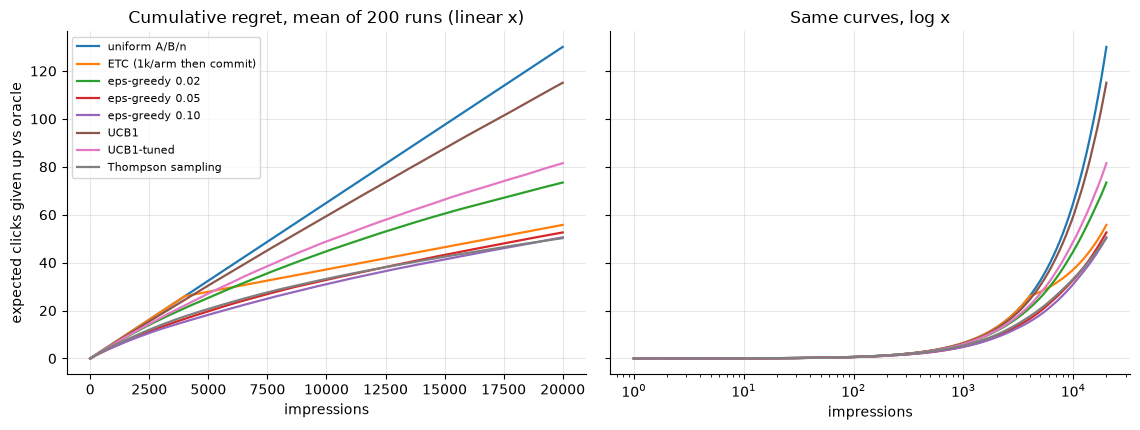

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
for name, res in race.items():
    m = res["regret"].mean(axis=1)
    for ax in axes:
        ax.plot(res["cps"], m, lw=1.6, label=name)
axes[1].set_xscale("log")
axes[0].set_title(f"Cumulative regret, mean of {N_RUNS} runs (linear x)")
axes[1].set_title("Same curves, log x")
for ax in axes:
    ax.set_xlabel("impressions")
axes[0].set_ylabel("expected clicks given up vs oracle")
axes[0].legend(fontsize=8, loc="upper left")
plt.show()

Reading the race (numbers from the table above):

- **Uniform A/B/n** is the straight line: ~130 clicks of regret and still climbing at a
  constant rate — the full exploration cost, paid on every impression, forever.
- **ETC** is piecewise: full price for the first 4,000 impressions, then a shallower
  line. It is *not* flat after commitment because with a 0.4pp gap, 1,000 pulls/arm
  commits to the wrong arm in about a third of replications (exactly the power
  calculation of Section 1) — and a committed mistake never gets corrected. That is
  "two-week A/B then ship" in miniature: pay full exploration *and* still ship the wrong
  arm uncomfortably often when the test is underpowered.
- **$\varepsilon$-greedy** curves bend, then go linear with slope
  $\propto \varepsilon$: exploration never adapts. Small $\varepsilon$ has a lower floor
  but corrects early mistakes more slowly (fatter p90).
- **UCB1 vs UCB1-tuned** is the theory-practice gap: with CTR-sized gaps, UCB1's
  worst-case radius keeps it close to uniform for the whole horizon, while the tuned
  variant's empirical-variance radius is ~2.5x narrower ($\sqrt{6.5}$) and actually
  concentrates traffic.
- **Thompson sampling** posts the best mean, the best p90, and the most traffic on the
  winner, but note *how*: on mean regret it only
  just edges the best fixed ε at this horizon — with a 0.4pp top-two gap nobody reaches
  their $O(\log T)$ asymptote in 20k impressions, a useful corrective to "TS crushes
  everything" folklore. Its real advantages are the tail (best p90 — no lock-in
  disasters), the most traffic on the winner, and the trend: its per-impression regret
  is still falling at the horizon while ε-greedy's has flattened at its permanent
  floor, so the gap only widens from here.

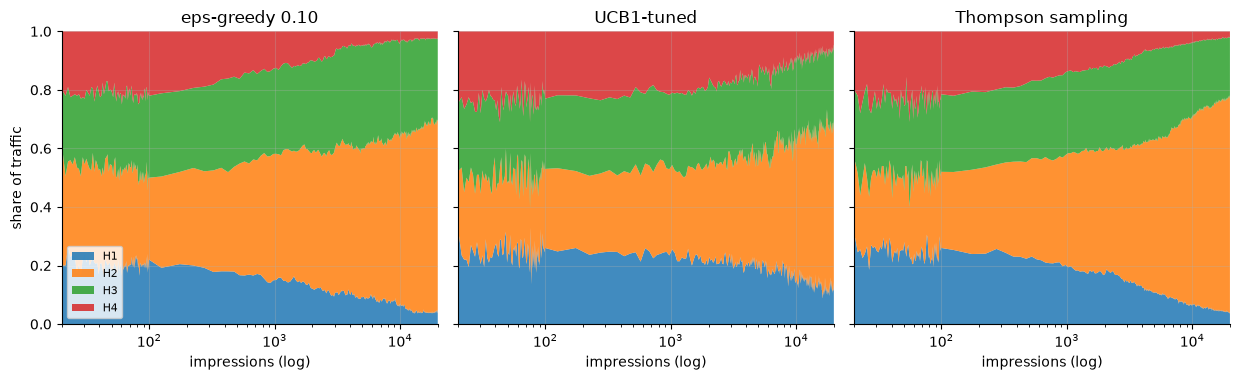

In [7]:
# How the traffic allocation evolves: share of impressions per arm in successive windows
show = ["eps-greedy 0.10", "UCB1-tuned", "Thompson sampling"]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), sharey=True)
for ax, name in zip(axes, show):
    res = race[name]
    cps = res["cps"]
    mean_pulls = res["pulls"].mean(axis=1)                       # (cps, K)
    dt = np.diff(cps)
    share = np.diff(mean_pulls, axis=0) / dt[:, None]            # instantaneous share
    mid = (cps[1:] + cps[:-1]) / 2
    ax.stackplot(mid, share.T, labels=arms.index, alpha=0.85)
    ax.set_xscale("log")
    ax.set_xlim(20, T_RACE)
    ax.set_ylim(0, 1)
    ax.set_title(name)
    ax.set_xlabel("impressions (log)")
axes[0].set_ylabel("share of traffic")
axes[0].legend(loc="lower left", fontsize=8)
plt.show()

The allocation view is what a PM sees on the dashboard: $\varepsilon$-greedy keeps a
permanent floor of traffic on every arm including the 2.8% one (that floor *is* its
linear regret); UCB1-tuned is still hedging between H2 and H3 at the horizon; Thompson
sampling funnels traffic to H2 while keeping a shrinking-but-alive share on H3 — exactly
proportional to the remaining chance H3 is actually better.

## 4. Thompson sampling is posterior sampling

[01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb) built the whole engine:
with a Beta$(\alpha_0,\beta_0)$ prior and $s_a$ clicks in $n_a$ impressions, the
posterior is Beta$(\alpha_0+s_a,\ \beta_0+n_a-s_a)$, and quantities like
$P(\text{arm } a \text{ is best} \mid \text{data})$ come from Monte Carlo over the
posteriors. Thompson sampling is one line on top: **draw one Monte Carlo sample per arm
and act on it**. Since the pulled arm is the argmax of one joint posterior draw,

$$ P(\text{pull } a \mid \text{data}) \;=\; P(\text{arm } a \text{ is best} \mid \text{data}) $$

— **probability matching**. That identity is why TS handles uncertainty naturally:

- An under-sampled arm has a wide posterior, so it occasionally produces a large draw
  and gets pulled — exploration happens *because* uncertainty is high, not on a fixed
  schedule.
- As data accumulates, posteriors sharpen, hopeless arms essentially never win the
  argmax, and exploration decays *automatically* — no $\varepsilon$ schedule to tune.
- Exploration is *directed*: it flows to arms that are plausibly best, not uniformly to
  all arms like $\varepsilon$-greedy's floor.

One replication, watched over time: the realized traffic share tracks the evolving
posterior $P(\text{best})$. (Single runs vary a lot — the race table's sd column — so we
show one that ends near the 200-run average of ~60% of traffic on H2.)

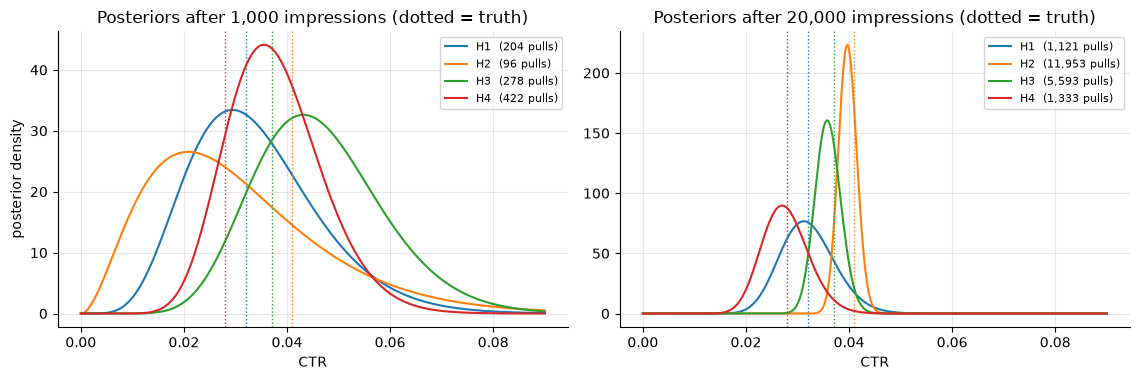

In [8]:
gen1 = child_rng(32)          # a replication whose final allocation is close to the TS average
s1, f1 = np.zeros(K), np.zeros(K)
arm_seq = np.empty(T_RACE, dtype=int)
post_hist = {}
cps1 = checkpoints(T_RACE)
ci = 0
for t in range(T_RACE):
    a = int(np.argmax(gen1.beta(s1 + 1, f1 + 1)))
    r = gen1.random() < TRUE_CTR[a]
    s1[a] += r
    f1[a] += 1 - r
    arm_seq[t] = a
    if ci < len(cps1) and t + 1 == cps1[ci]:
        post_hist[t + 1] = (s1.copy(), f1.copy())
        ci += 1

# posterior densities early vs late
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharex=True)
grid = np.linspace(0.0, 0.09, 400)
for ax, t_show in zip(axes, [1000, T_RACE]):
    s_t, f_t = post_hist[t_show]
    for aa in range(K):
        ax.plot(grid, stats.beta.pdf(grid, s_t[aa] + 1, f_t[aa] + 1),
                label=f"{arms.index[aa]}  ({int(s_t[aa] + f_t[aa]):,} pulls)")
        ax.axvline(TRUE_CTR[aa], color=f"C{aa}", ls=":", lw=1)
    ax.set_title(f"Posteriors after {t_show:,} impressions (dotted = truth)")
    ax.set_xlabel("CTR")
    ax.legend(fontsize=8)
axes[0].set_ylabel("posterior density")
plt.show()

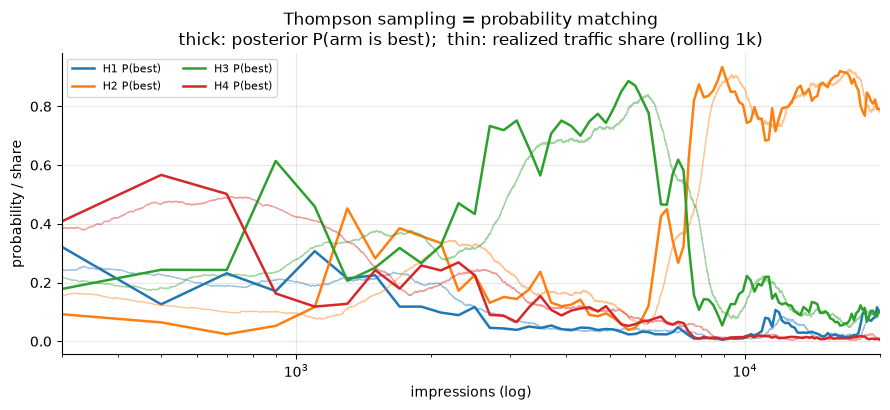

In [9]:
# probability matching: P(best | data) vs the realized traffic share, same replication
sub = cps1[cps1 >= 100][::4]
p_best = np.empty((len(sub), K))
gen_mc = child_rng(321)
for i, t_show in enumerate(sub):
    s_t, f_t = post_hist[t_show]
    draws = gen_mc.beta(s_t + 1, f_t + 1, size=(4000, K))
    p_best[i] = np.bincount(draws.argmax(axis=1), minlength=K) / 4000

onehot = pd.get_dummies(pd.Series(arm_seq)).astype(float)
roll_share = onehot.rolling(1000, min_periods=300).mean().to_numpy()

fig, ax = plt.subplots(figsize=(9, 4.2))
for aa in range(K):
    ax.plot(sub, p_best[:, aa], color=f"C{aa}", lw=1.8, label=f"{arms.index[aa]} P(best)")
    ax.plot(np.arange(T_RACE), roll_share[:, aa], color=f"C{aa}", lw=1, alpha=0.45)
ax.set_xscale("log")
ax.set_xlim(300, T_RACE)
ax.set_title("Thompson sampling = probability matching\n"
             "thick: posterior P(arm is best);  thin: realized traffic share (rolling 1k)")
ax.set_xlabel("impressions (log)")
ax.set_ylabel("probability / share")
ax.legend(fontsize=8, ncol=2)
plt.show()

The thin lines (what TS actually did) shadow the thick lines (what the posterior
believes) — allocation *is* belief. Two practical notes a senior candidate should add:

- **Priors plug in directly.** Everything from
  [01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb) about pseudo-count
  priors applies: seeding a new headline with Beta(40, 960) (a "CTRs live near 4%"
  prior) prevents the wild early over-exploration of a flat prior. With many related
  arms, the prior should come from a hierarchical model over past headlines —
  [03_hierarchical_models.ipynb](./03_hierarchical_models.ipynb).
- **TS optimizes; it does not test.** $P(\text{best})$ here is the same quantity you'd
  use for a ship decision in notebook 01, but the *traffic* it controls makes the
  collected data non-experimental — Section 7.

## 5. Constraint 1: batched and delayed updates

The textbook bandit updates after every impression. Production rarely does: models
retrain nightly, click logs land in the warehouse hourly, conversions attribute with
delay. Between refreshes the policy acts on a **stale snapshot** of the counts.

The failure mode is not symmetric across algorithms. UCB is **deterministic given the
data**: with frozen counts it computes the same index all night and hammers a single arm
for the whole batch. Thompson sampling **re-randomizes every impression** — each pull is
a fresh posterior draw — so even with a stale posterior the batch is spread across all
still-plausible arms. (TS's robustness to delayed/batched updates was a headline finding
of Chapelle & Li's 2011 empirical study.)

To isolate what batching destroys, we switch to an easier arm set — promo-email subject
lines with cleaner 1.5–3pp gaps, where both online algorithms perform well — and then
throttle updates: per-impression, nightly (10 updates over the horizon), and 4 updates
total.

In [10]:
P_BATCH = np.array([0.050, 0.035, 0.028, 0.020])    # promo subject lines: cleaner separation
BATCHES = [1, 2000, 5000]                           # online / nightly / 4 updates total
batched = {}
for b in BATCHES:
    batched[("Thompson sampling", b)] = simulate(thompson, P_BATCH, T_RACE, N_RUNS, seed=(30, b), batch=b)
    batched[("UCB1-tuned", b)] = simulate(make_ucb(tuned=True), P_BATCH, T_RACE, N_RUNS, seed=(31, b), batch=b)

batch_tbl = pd.DataFrame(
    {alg: {b: batched[(alg, b)]["regret"][-1].mean() for b in BATCHES}
     for alg in ["Thompson sampling", "UCB1-tuned"]})
batch_tbl.index.name = "batch size"
print("mean final regret (clicks) by update batch size:")
print(batch_tbl.round(1).to_string())
print(f"\nuniform A/B/n on these arms: {(P_BATCH.max() - P_BATCH).mean() * T_RACE:.0f}")

mean final regret (clicks) by update batch size:
            Thompson sampling  UCB1-tuned
batch size                               
1                        41.7       106.4
2000                     54.6       176.4
5000                     93.4       206.6

uniform A/B/n on these arms: 335


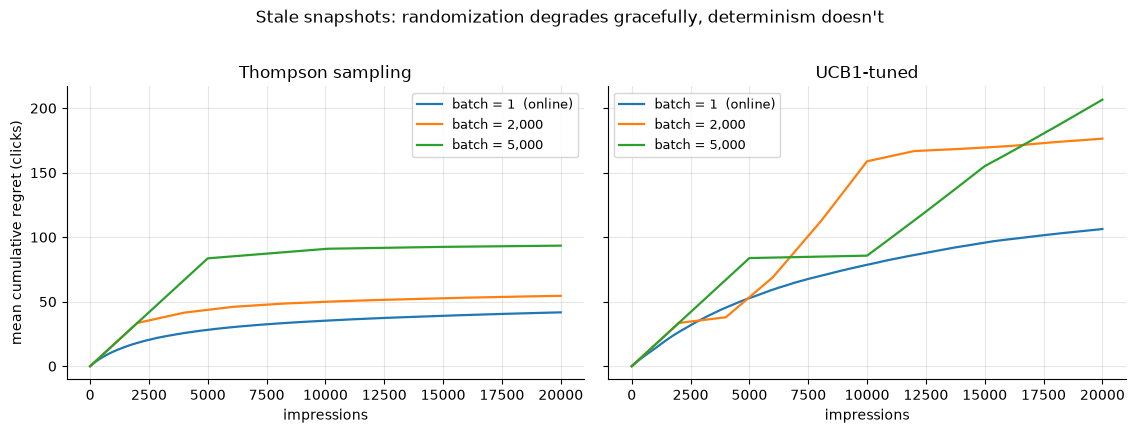

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, alg in zip(axes, ["Thompson sampling", "UCB1-tuned"]):
    for b in BATCHES:
        res = batched[(alg, b)]
        ax.plot(res["cps"], res["regret"].mean(axis=1), lw=1.6,
                label=f"batch = {b:,}" + ("  (online)" if b == 1 else ""))
    ax.set_title(alg)
    ax.set_xlabel("impressions")
    ax.legend(fontsize=9)
axes[0].set_ylabel("mean cumulative regret (clicks)")
fig.suptitle("Stale snapshots: randomization degrades gracefully, determinism doesn't", y=1.02)
plt.show()

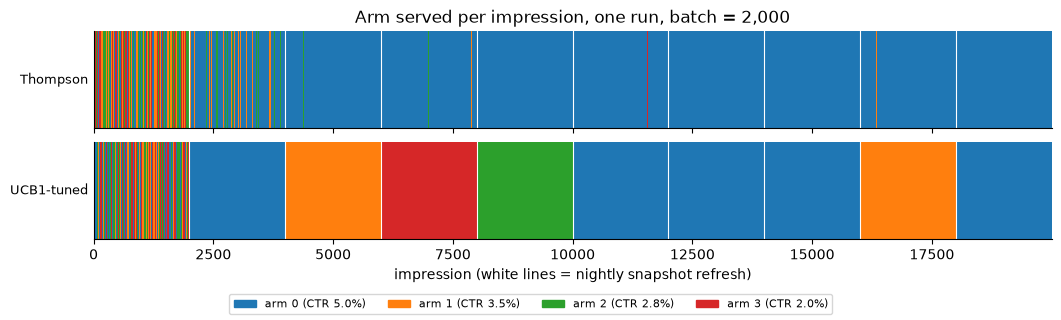

In [12]:
# the mechanism, one replication at batch=2000: which arm each impression got
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches


def arm_trace(policy, true_p, T, seed, batch):
    gen = child_rng(*seed)
    k = len(true_p)
    s, f = np.zeros((1, k)), np.zeros((1, k))
    snap_s, snap_f = s.copy(), f.copy()
    trace = np.empty(T, dtype=int)
    for t in range(T):
        if t % batch == 0:
            snap_s, snap_f = s.copy(), f.copy()
        a = policy(snap_s, snap_f, t, gen)
        r = gen.random(1) < true_p[a]
        s[0, a[0]] += r[0]
        f[0, a[0]] += ~r[0]
        trace[t] = a[0]
    return trace


cmap4 = ListedColormap([f"C{i}" for i in range(len(P_BATCH))])
fig, axes = plt.subplots(2, 1, figsize=(10.5, 3.1), sharex=True, layout="constrained")
for ax, (name, pol, sd) in zip(axes, [("Thompson", thompson, 320),
                                      ("UCB1-tuned", make_ucb(tuned=True), 330)]):
    tr = arm_trace(pol, P_BATCH, T_RACE, (sd,), batch=2000)
    ax.imshow(tr[None, :], aspect="auto", cmap=cmap4, interpolation="nearest",
              vmin=-0.5, vmax=len(P_BATCH) - 0.5)
    for edge in range(2000, T_RACE, 2000):
        ax.axvline(edge, color="w", lw=0.8)
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
    ax.grid(False)
axes[1].set_xlabel("impression (white lines = nightly snapshot refresh)")
axes[0].set_title("Arm served per impression, one run, batch = 2,000")
fig.legend(handles=[mpatches.Patch(color=f"C{i}", label=f"arm {i} (CTR {p:.1%})")
                    for i, p in enumerate(P_BATCH)],
           loc="outside lower center", ncol=4, fontsize=8)
plt.show()

The regret table is the quantitative story: with nightly updates TS gives back ~13
clicks (42 → 55) while UCB1-tuned gives back ~70 (106 → 176); at 4 updates total, UCB's
regret (~207) is well over half of *not learning at all* (uniform = 335), while TS
(~93) retains most of its edge. The trace plot is the mechanism: between refreshes UCB
serves a **monoculture** — every impression that "night" gets the same, possibly
mediocre, arm chosen by stale counts — while TS keeps hedging within each batch because
every impression is a fresh draw from the (stale) posterior. Practical rules:

- If you must batch (you must), prefer a **randomized** policy: TS as-is, or "UCB with
  dithering". The batch is then an unbiased draw from the current allocation
  distribution rather than a monoculture.
- Batching is also the honest model of **delayed rewards**: acting on counts up to the
  last refresh is the same as every reward arriving with up-to-one-batch delay. If your
  true reward (e.g. conversion) lags by days, your effective batch is days long —
  size the horizon accordingly, or optimize a fast proxy and *validate* it against the
  slow truth (Pitfall 2).

## 6. Constraint 2: non-stationarity — a drifting arm defeats a stale posterior

Headlines fatigue, competitors react, seasonality moves baselines. Standard TS assumes
stationary arms: its posterior weighs an impression from this morning equally with one
from last month. Once an arm has tens of thousands of pseudo-counts, its posterior mean
is a **lifetime average** that can stay high long after the arm's current rate has
collapsed — and because the posterior is also *narrow*, TS barely re-explores to find
out.

Scenario: H-breaking starts hot (6%) and fatigues to 2%; two evergreen arms hold at 4.0%
and 4.6%. The best arm switches at impression 8,500. Fixes that keep the posterior
*young*:

- **Sliding window**: only the last $W$ pulls count. Effective sample size $\le W$.
- **Discounting**: after each impression, multiply all counts by $\gamma$ before adding
  the new observation ($s \leftarrow \gamma s + r$). Effective sample size is capped at
  $1/(1-\gamma)$; old evidence decays geometrically.

Both deliberately *throw away statistical efficiency* to buy adaptivity — the window/
discount horizon should match the drift timescale you need to track.

In [13]:
T_NS = 20_000
tt = np.arange(T_NS)
p_drift = np.column_stack([
    np.full(T_NS, 0.040),                                          # evergreen A
    np.clip(0.060 - 0.004 * (tt - 5000) / 1000.0, 0.020, 0.060),   # breaking-news arm: fatigues
    np.full(T_NS, 0.046),                                          # evergreen B
])
NS_NAMES = ["evergreen-A", "breaking", "evergreen-B"]
CROSS = int(np.argmax(p_drift.argmax(axis=1) != 1))                # first t where 'breaking' is no longer best
print(f"best arm switches from 'breaking' to 'evergreen-B' at impression {CROSS:,}")


class TSAgent:
    """Beta-Bernoulli TS, vectorized across runs; optional discounting or sliding window."""

    def __init__(self, n_runs, k, gamma=None, window=None):
        self.s = np.zeros((n_runs, k))
        self.f = np.zeros((n_runs, k))
        self.gamma, self.window = gamma, window
        if window is not None:
            self.arm_buf = np.zeros((n_runs, window), dtype=np.int64)
            self.r_buf = np.zeros((n_runs, window), dtype=np.int64)
        self.t = 0
        self.rows = np.arange(n_runs)

    def act(self, gen):
        return np.argmax(gen.beta(self.s + 1.0, self.f + 1.0), axis=1)

    def update(self, a, r):
        if self.gamma is not None:
            self.s *= self.gamma
            self.f *= self.gamma
        if self.window is not None:
            p = self.t % self.window
            if self.t >= self.window:                    # evict the observation leaving the window
                oa, orr = self.arm_buf[:, p], self.r_buf[:, p]
                self.s[self.rows, oa] -= orr
                self.f[self.rows, oa] -= 1 - orr
            self.arm_buf[:, p] = a
            self.r_buf[:, p] = r
        self.s[self.rows, a] += r
        self.f[self.rows, a] += 1 - r
        self.t += 1


class UniformAgent:
    def __init__(self, n_runs, k):
        self.n, self.k = n_runs, k

    def act(self, gen):
        return gen.integers(0, self.k, self.n)

    def update(self, a, r):
        pass


def simulate_drift(agent, p_t, n_runs, seed, fatigued=1):
    T, k = p_t.shape
    gen = child_rng(*seed)
    best_p = p_t.max(axis=1)
    best_arm = p_t.argmax(axis=1)
    cum = np.zeros(n_runs)
    reg_mean = np.empty(T)
    share_best = np.empty(T)
    share_fat = np.empty(T)
    for t in range(T):
        a = agent.act(gen)
        r = (gen.random(n_runs) < p_t[t, a]).astype(np.int64)
        agent.update(a, r)
        cum += best_p[t] - p_t[t, a]
        reg_mean[t] = cum.mean()
        share_best[t] = (a == best_arm[t]).mean()
        share_fat[t] = (a == fatigued).mean()
    return reg_mean, share_best, share_fat, cum


drift_runs = {}
drift_specs = {
    "TS (stationary posterior)": (dict(), (40,)),
    "TS discounted (gamma=0.999)": (dict(gamma=0.999), (41,)),
    "TS sliding window (W=1500)": (dict(window=1500), (42,)),
    "uniform A/B/n": (None, (43,)),
}
for name, (kw, sd) in drift_specs.items():
    agent = UniformAgent(N_RUNS, 3) if kw is None else TSAgent(N_RUNS, 3, **kw)
    drift_runs[name] = simulate_drift(agent, p_drift, N_RUNS, seed=sd)

drift_tbl = pd.DataFrame({
    name: {"final regret": res[3].mean(),
           "regret in last 5k": res[0][-1] - res[0][-5001],
           "% on fatigued arm, 10k-15k": 100 * res[2][10000:15000].mean(),
           "% on fatigued arm, last 5k": 100 * res[2][-5000:].mean()}
    for name, res in drift_runs.items()}).T
print(drift_tbl.round(1).to_string())

best arm switches from 'breaking' to 'evergreen-B' at impression 8,501


                             final regret  regret in last 5k  % on fatigued arm, 10k-15k  % on fatigued arm, last 5k
TS (stationary posterior)           142.6               55.0                        68.9                        39.2
TS discounted (gamma=0.999)         101.4               24.3                        20.8                        11.2
TS sliding window (W=1500)           93.1               21.3                        18.6                         8.9
uniform A/B/n                       174.5               53.3                        33.4                        33.3


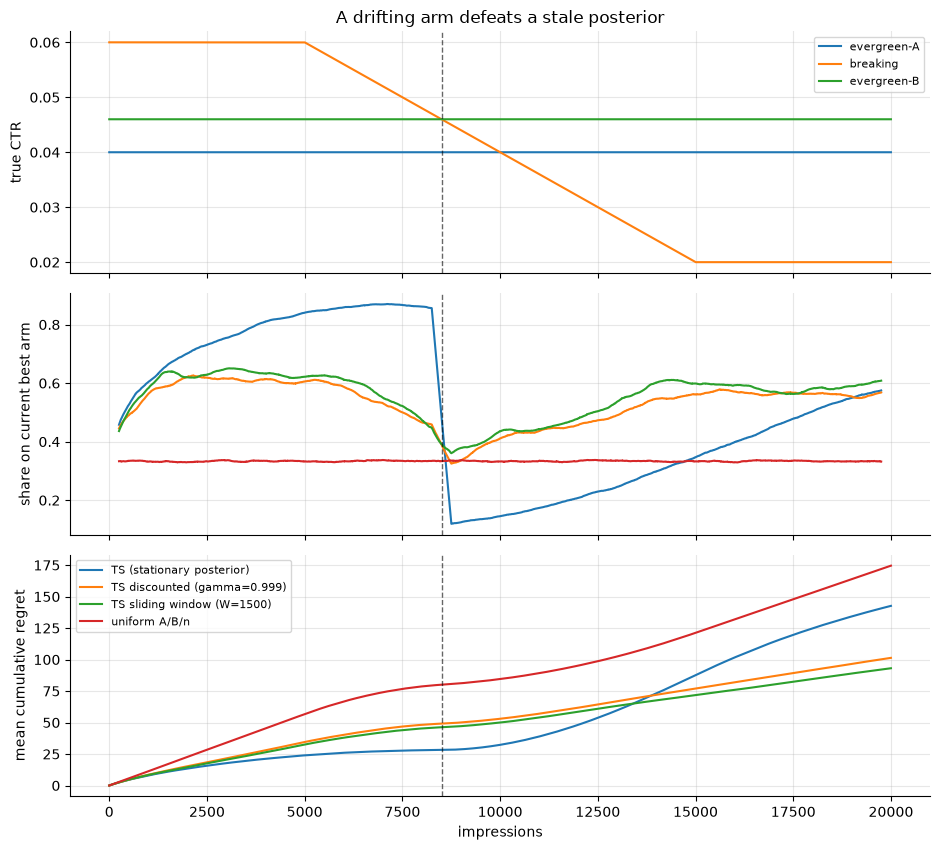

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(9.5, 8.6), sharex=True)
for aa in range(3):
    axes[0].plot(tt, p_drift[:, aa], label=NS_NAMES[aa])
axes[0].set_ylabel("true CTR")
axes[0].set_title("A drifting arm defeats a stale posterior")
axes[0].legend(fontsize=8)

kern = np.ones(500) / 500
for name, res in drift_runs.items():
    axes[1].plot(np.arange(len(res[1]) - 499) + 250, np.convolve(res[1], kern, mode="valid"),
                 lw=1.5, label=name)
    axes[2].plot(res[0], lw=1.5, label=name)
axes[1].set_ylabel("share on current best arm")
axes[2].set_ylabel("mean cumulative regret")
axes[2].set_xlabel("impressions")
axes[2].legend(fontsize=8, loc="upper left")
for ax in axes:
    ax.axvline(CROSS, color="k", ls="--", lw=1, alpha=0.6)
plt.show()

After the crossover (dashed line) the stationary posterior keeps pouring traffic into
the fatigued arm — its *lifetime-average* posterior mean is still the highest, and with
thousands of pseudo-counts the posterior is too narrow to explore its way out: in the
10k–15k window it still sends ~69% of impressions to an arm sliding toward 2%. By the
final 5k impressions the once-dominant policy is accruing regret as fast as uniform
A/B/n — it has fully surrendered the advantage it was hired for. The windowed and
discounted variants shed the fatigued arm within roughly one window/discount-horizon
and re-converge on the new best arm (their residual regret is mostly the
harder-to-resolve 4.0% vs 4.6% contest with a capped effective sample size).

Field notes:

- Match $W$ (or $1/(1-\gamma)$) to the drift timescale; the price is permanently higher
  variance (an effective-$n$ cap), which is why you don't discount "just in case" when
  arms are genuinely stable.
- Alternatives seen in production: scheduled posterior resets when creative rotates,
  inflating posterior variance on a schedule, or modeling time (day-of-week, decay) as
  context (Section 8). Detecting that drift is happening at all is a monitoring problem
  — see [../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb).

## 7. Bandit data lies: adaptive sampling bias

The most under-appreciated fact in this chapter: **the empirical arm means from a bandit
are biased estimates of the true arm means** — you cannot read the dashboard's
per-arm CTRs as unbiased lifts.

The mechanism is adaptive feedback. If an arm gets unlucky early, the bandit starves it
of traffic, so its mean stays *frozen at the unlucky value*; if it gets lucky, the
bandit feeds it, and the extra data pulls the mean back down toward truth. Downward
errors persist, upward errors self-correct — so sample means are biased **downward**,
and the bias is worst for arms the bandit abandoned (Nie et al. 2018, "Why adaptively
collected data have negative bias"). It is regression-to-the-mean weaponized by the
allocation rule (the trap family of
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).

Three arms (5%, 4%, 3%), a short 2,000-impression horizon where adaptivity bites
hardest, 4,000 replications; a uniform A/B on identical data volume is the control
condition.

In [15]:
P_BIAS = np.array([0.05, 0.04, 0.03])
T_BIAS, R_BIAS = 2000, 4000
ts_b = simulate(thompson, P_BIAS, T_BIAS, R_BIAS, seed=50)
ab_b = simulate(uniform_policy, P_BIAS, T_BIAS, R_BIAS, seed=51)


def arm_means(res):
    pulls = res["succ"] + res["fail"]
    assert pulls.min() >= 1, "an arm was never pulled"
    return res["succ"] / pulls, pulls


ts_hat, ts_pulls = arm_means(ts_b)
ab_hat, _ = arm_means(ab_b)

bias_tbl = pd.DataFrame({
    "true p": P_BIAS,
    "TS mean p_hat": ts_hat.mean(axis=0),
    "TS bias (pp)": 100 * (ts_hat.mean(axis=0) - P_BIAS),
    "TS bias SE (pp)": 100 * ts_hat.std(axis=0) / np.sqrt(R_BIAS),
    "TS median pulls": np.median(ts_pulls, axis=0),
    "A/B bias (pp)": 100 * (ab_hat.mean(axis=0) - P_BIAS),
}, index=["arm 1 (best)", "arm 2", "arm 3"])
print(bias_tbl.round(3).to_string())

lift_ts = 100 * (ts_hat[:, 0] - ts_hat[:, 1]).mean()
lift_ab = 100 * (ab_hat[:, 0] - ab_hat[:, 1]).mean()
print(f"\napparent lift arm1-arm2:  TS {lift_ts:.3f}pp | A/B {lift_ab:.3f}pp | truth 1.000pp")

              true p  TS mean p_hat  TS bias (pp)  TS bias SE (pp)  TS median pulls  A/B bias (pp)
arm 1 (best)    0.05          0.047        -0.254            0.015           1202.5         -0.006
arm 2           0.04          0.035        -0.490            0.018            483.0          0.019
arm 3           0.03          0.025        -0.495            0.018            254.5         -0.011

apparent lift arm1-arm2:  TS 1.237pp | A/B 0.976pp | truth 1.000pp


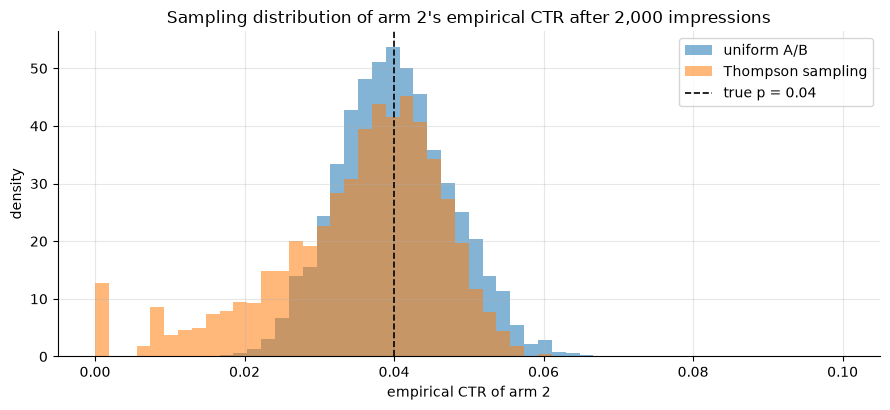

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(0, 0.10, 55)
ax.hist(ab_hat[:, 1], bins=bins, alpha=0.55, density=True, label="uniform A/B")
ax.hist(ts_hat[:, 1], bins=bins, alpha=0.55, density=True, label="Thompson sampling")
ax.axvline(P_BIAS[1], color="k", ls="--", lw=1.2, label="true p = 0.04")
ax.set_title("Sampling distribution of arm 2's empirical CTR after 2,000 impressions")
ax.set_xlabel("empirical CTR of arm 2")
ax.set_ylabel("density")
ax.legend()
plt.show()

Under uniform allocation the estimate is unbiased and tight. Under TS the same arm's
estimate is biased low by about half a point — half of its true 1pp gap to the best arm
— and the distribution has a long left tail of replications where the arm was written
off early. Even the *winning* arm is biased down (~0.25pp), because its unlucky
stretches also trigger reduced sampling. The na&iuml;ve "winner vs arm 2" lift read off
the bandit consequently *overstates* the truth.

What to do about it (in increasing order of rigor):

1. **Don't reuse bandit data for inference** — treat the bandit as an optimizer, run a
   proper A/B when you need an estimate.
2. **Keep a uniform holdout** (5–10% of traffic assigned uniformly at random): unbiased
   estimates by construction, at a small, known regret cost — Exercise 3.
3. **Reweight**: log propensities and use IPW/doubly-robust estimators (Pitfall 3, and
   [../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb](../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb)).

### Bandit vs A/B: the decision framework

The one-line answer: **bandits optimize, experiments infer.** Regret minimization and
unbiased effect estimation are *competing objectives* — the better a policy exploits,
the more biased and starved the data on losing arms.

| Choose a **bandit** when... | Choose an **A/B test** when... |
|---|---|
| The decision is *which arm to serve*, continuously | The decision is *ship/no-ship*, once, with sign-off |
| Many arms, short arm lifetime (headlines, creatives, promos) | Few arms, long-lived change (pricing, ranking algorithm) |
| Per-impression opportunity cost is real and immediate | Learning value dominates; test cost is budgeted |
| Reward is fast (click, dwell) | Reward is slow/delayed (retention, LTV) or a guardrail suite |
| A biased-but-good arm choice is fine | You need unbiased lift with CIs for the org / finance |
| Stakeholders accept an allocation that shifts daily | Fixed allocation needed for SRM checks, segment analysis, interference designs ([../02_ab_testing/06_advanced_designs_interference.ipynb](../02_ab_testing/06_advanced_designs_interference.ipynb)) |

Hybrids are common and sensible: bandit with a permanent uniform holdout; A/B to pick
the champion, bandit to tune it; bandit for the 20 headline variants inside the A/B-ed
product surface.

## 8. Contextual bandits: LinUCB in ~40 lines

So far the best arm is the best arm for everyone. In reality the best headline depends
on *who is looking*: device, engagement history, time of day. A **contextual bandit**
observes a feature vector $x_t$ before choosing, and learns a reward model per arm.

**LinUCB** (disjoint version, Li et al. 2010 — built for exactly this news-headline
problem) assumes $\mathbb{E}[r \mid x, a] = x^\top \theta_a$ and keeps a ridge
regression per arm. With $A_a = \lambda I + \sum x x^\top$ (over pulls of $a$) and
$b_a = \sum r x$, it pulls

$$ \arg\max_a \; \underbrace{x^\top \hat\theta_a}_{\text{predicted reward}}
   + \alpha \underbrace{\sqrt{x^\top A_a^{-1} x}}_{\text{model uncertainty at } x},
   \qquad \hat\theta_a = A_a^{-1} b_a $$

— UCB's optimism, but the confidence radius now depends on *where in feature space* the
arm has been tried. Context: `[1, is_mobile, engagement]`. Truth (unknown to policies):
punchy headlines win on mobile, in-depth wins on engaged desktop — so no single arm is
best overall, and any context-free policy has a regret floor.

In [17]:
THETA = np.array([
    [0.030, 0.025, 0.000],    # arm 0 "short-punchy":  strong on mobile
    [0.042, -0.020, 0.010],   # arm 1 "in-depth":      strong on engaged desktop
    [0.036, 0.005, -0.008],   # arm 2 "listicle":      middling everywhere
])
CTX_ARMS = ["short-punchy", "in-depth", "listicle"]


def draw_context(gen):
    return np.array([1.0, float(gen.random() < 0.55), float(np.clip(gen.normal(), -3, 3))])


def true_ctr(x):
    return np.clip(THETA @ x, 0.005, 0.5)


def run_contextual(kind, T, gen, alpha=1.0, lam=1.0):
    """One replication of LinUCB / context-free TS / uniform on the same context stream."""
    d, k = 3, 3
    A_inv = np.stack([np.eye(d) / lam for _ in range(k)])
    b = np.zeros((k, d))
    s = np.zeros(k)
    f = np.zeros(k)
    reg = np.empty(T)
    for t in range(T):
        x = draw_context(gen)
        p = true_ctr(x)
        if kind == "linucb":
            scores = np.array([b[a] @ A_inv[a] @ x + alpha * np.sqrt(x @ A_inv[a] @ x)
                               for a in range(k)])
            a = int(scores.argmax())
        elif kind == "ts":
            a = int(np.argmax(gen.beta(s + 1, f + 1)))
        else:
            a = int(gen.integers(k))
        r = float(gen.random() < p[a])
        if kind == "linucb":                       # Sherman-Morrison rank-1 update of A_inv
            Ax = A_inv[a] @ x
            A_inv[a] -= np.outer(Ax, Ax) / (1.0 + x @ Ax)
            b[a] += r * x
        elif kind == "ts":
            s[a] += r
            f[a] += 1 - r
        reg[t] = p.max() - p[a]
    return reg.cumsum(), A_inv, b


T_CTX, R_CTX = 4000, 20
ctx_curves = {}
theta_fits = []                       # fitted theta_hat = A^-1 b from each LinUCB replication
for j, kind in enumerate(["linucb", "ts", "uniform"]):
    curves = []
    for run in range(R_CTX):
        cum, A_inv_r, b_r = run_contextual(kind, T_CTX, child_rng(60 + j, run))
        curves.append(cum)
        if kind == "linucb":
            theta_fits.append(np.einsum("kij,kj->ki", A_inv_r, b_r))
    ctx_curves[kind] = np.array(curves)
theta_bar = np.mean(theta_fits, axis=0)

ctx_tbl = pd.DataFrame({
    kind: {"mean final regret": ctx_curves[kind][:, -1].mean(),
           "sd": ctx_curves[kind][:, -1].std()}
    for kind in ctx_curves}).T
print(ctx_tbl.round(1).to_string())

         mean final regret   sd
linucb                27.8  5.5
ts                    43.6  6.0
uniform               53.6  0.7


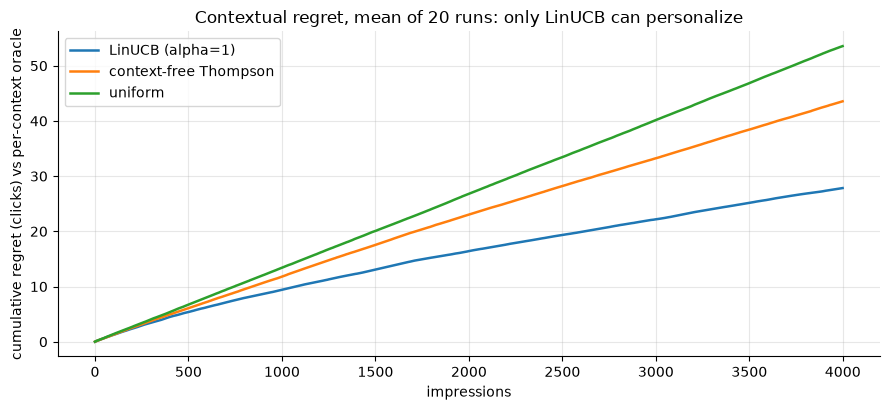

mean fitted theta per arm vs truth:
  short-punchy  fitted [ 0.0265  0.0265 -0.0006]   true [0.03  0.025 0.   ]
  in-depth      fitted [ 0.0395 -0.0237  0.0113]   true [ 0.042 -0.02   0.01 ]
  listicle      fitted [ 0.0318  0.0019 -0.0065]   true [ 0.036  0.005 -0.008]

 mobile  engagement  LinUCB pick    true best
    1.0        -1.5 short-punchy short-punchy
    1.0         0.0 short-punchy short-punchy
    1.0         1.5 short-punchy short-punchy
    0.0        -1.5     listicle     listicle
    0.0         0.0     in-depth     in-depth
    0.0         1.5     in-depth     in-depth


In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = {"linucb": "LinUCB (alpha=1)", "ts": "context-free Thompson", "uniform": "uniform"}
for kind, arr in ctx_curves.items():
    ax.plot(np.arange(T_CTX), arr.mean(axis=0), lw=1.8, label=labels[kind])
ax.set_title(f"Contextual regret, mean of {R_CTX} runs: only LinUCB can personalize")
ax.set_xlabel("impressions")
ax.set_ylabel("cumulative regret (clicks) vs per-context oracle")
ax.legend()
plt.show()

# what did LinUCB learn? mean fitted coefficients, and its decision rule on a probe grid
print("mean fitted theta per arm vs truth:")
for a, nm in enumerate(CTX_ARMS):
    print(f"  {nm:13s} fitted {np.round(theta_bar[a], 4)}   true {THETA[a]}")

probe = pd.DataFrame([(m, e) for m in (1.0, 0.0) for e in (-1.5, 0.0, 1.5)],
                     columns=["mobile", "engagement"])
X_probe = np.column_stack([np.ones(len(probe)), probe["mobile"], probe["engagement"]])
probe["LinUCB pick"] = [CTX_ARMS[i] for i in (X_probe @ theta_bar.T).argmax(axis=1)]
probe["true best"] = [CTX_ARMS[i] for i in (X_probe @ THETA.T).argmax(axis=1)]
print()
print(probe.to_string(index=False))

Context-free Thompson does the best it can — converge to the arm with the best *average*
CTR — but that leaves a permanent per-impression gap to the per-context oracle: its
regret goes linear while LinUCB's flattens. The probe table (using the mean fitted model
across the 20 replications) shows LinUCB recovered the whole qualitative policy from
Bernoulli clicks alone: punchy on mobile, in-depth on engaged desktop, listicle for
disengaged desktop — and the fitted coefficients land close to the truth.

Production notes: real systems use one shared model with arm features rather than
disjoint models (generalizes across arms, handles new arms), logistic rather than linear
reward heads, and are evaluated *offline* with the logged-propensity replay method
before serving — which only works if propensities were logged (Pitfall 3).

## 9. Pitfalls

### Pitfall 1: greedy (ε = 0) — the average hides the disasters

Pure greedy looks harmless in a mean-regret table but is catastrophic in distribution.
With rare rewards it effectively runs "first arm to convert wins forever": once an arm
has the only success, nothing can dethrone it, because the other arm's mean is 0 and is
never sampled again. The mean regret hides a bimodal reality.

greedy (eps=0)  mean regret   22.2 | % of runs giving the worse arm most traffic: 44.4%
Thompson        mean regret   11.5 | % of runs giving the worse arm most traffic: 9.1%


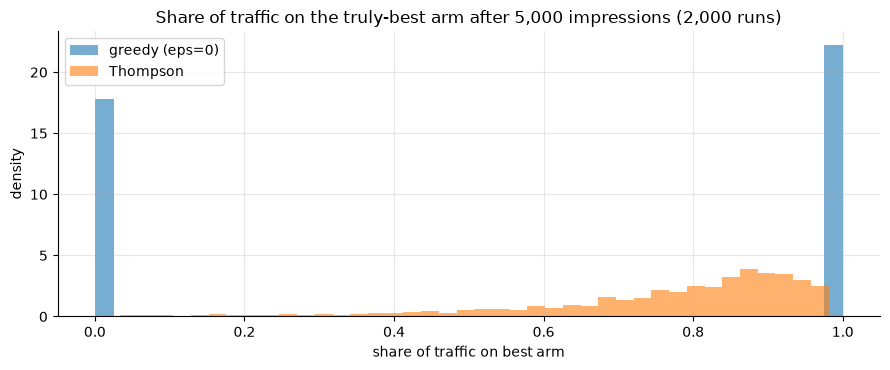

In [19]:
P_GREEDY = np.array([0.05, 0.04])
greedy_res = simulate(make_eps_greedy(0.0), P_GREEDY, 5000, 2000, seed=70)
ts_res = simulate(thompson, P_GREEDY, 5000, 2000, seed=71)

for name, res in [("greedy (eps=0)", greedy_res), ("Thompson", ts_res)]:
    share_best = res["pulls"][-1, :, 0] / 5000
    print(f"{name:15s} mean regret {res['regret'][-1].mean():6.1f} | "
          f"% of runs giving the worse arm most traffic: {100 * (share_best < 0.5).mean():.1f}%")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(greedy_res["pulls"][-1, :, 0] / 5000, bins=40, alpha=0.6, density=True, label="greedy (eps=0)")
ax.hist(ts_res["pulls"][-1, :, 0] / 5000, bins=40, alpha=0.6, density=True, label="Thompson")
ax.set_title("Share of traffic on the truly-best arm after 5,000 impressions (2,000 runs)")
ax.set_xlabel("share of traffic on best arm")
ax.set_ylabel("density")
ax.legend()
plt.show()

Greedy's histogram is two spikes: locked on the right arm, or locked on the wrong one —
in nearly half the replications. Any amount of principled exploration (TS's posterior
tail, a nonzero ε, an optimism bonus) removes the permanent-lock failure mode. If you
see a "bandit" in the wild with no exploration term, this is its failure distribution.

### Pitfall 2: optimizing the click when the business wants the conversion

A bandit optimizes *exactly* the reward you wire in. Feed it clicks when the goal is
conversions and it will faithfully find clickbait: the arm ordering on CTR need not
match the ordering on value. And the honest metric is often 20–50x rarer, so learning on
it is slower — the real design decision is proxy speed vs metric truth (plus the delay
machinery of Section 5).

In [20]:
CTR2 = np.array([0.060, 0.040])          # clickbait vs honest headline: clicks per impression
CVR2 = np.array([0.020, 0.080])          # conversions per click
VALUE = CTR2 * CVR2                      # conversions per impression: [0.0012, 0.0032]
print(f"conversions per impression by arm: {VALUE}")

click_ts = simulate(thompson, CTR2, T_RACE, N_RUNS, seed=80)     # rewarded on clicks
value_ts = simulate(thompson, VALUE, T_RACE, N_RUNS, seed=81)    # rewarded on conversions

pulls_click = click_ts["pulls"][-1].mean(axis=0)
conv_click = (pulls_click * VALUE).sum()
conv_value = T_RACE * VALUE.max() - value_ts["regret"][-1].mean()
oracle = T_RACE * VALUE.max()
tbl = pd.DataFrame({
    "% traffic to clickbait": [100 * pulls_click[0] / T_RACE,
                               100 * value_ts["pulls"][-1, :, 0].mean() / T_RACE],
    "expected conversions": [conv_click, conv_value],
}, index=["TS rewarded on clicks", "TS rewarded on conversions"])
print(tbl.round(1).to_string())
print(f"always-best oracle: {oracle:.0f} conversions")

conversions per impression by arm: [0.0012 0.0032]


                            % traffic to clickbait  expected conversions
TS rewarded on clicks                         95.6                  25.8
TS rewarded on conversions                    13.3                  58.7
always-best oracle: 64 conversions


The click-rewarded bandit *succeeds perfectly at the wrong objective*, parking ~95% of
traffic on the clickbait arm and forfeiting more than half the achievable conversions.
The conversion-rewarded bandit gets close to the oracle even at a 0.32% reward rate —
but only because 20k impressions is enough to resolve a 0.12pp vs 0.32pp gap; with
rarer rewards or slower attribution you'd optimize a validated proxy instead. Same
proxy-metric discipline as
[../08_product_analytics/01_metrics_and_growth.ipynb](../08_product_analytics/01_metrics_and_growth.ipynb).

### Pitfall 3: not logging propensities

Section 7 showed adaptive data is biased. The cheapest insurance is to **log the
probability that each impression's arm was chosen** ($\pi_t$). Then inverse-propensity
weighting rescues unbiased arm means from arbitrarily adaptive traffic:
$\hat\mu_a^{IPS} = \frac{1}{T}\sum_t \frac{\mathbb{1}[A_t = a]\, r_t}{\pi_t(A_t)}$ —
each term is conditionally unbiased for $\mu_a$ regardless of how the policy adapted
(the bandit version of
[../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb](../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb)).
ε-greedy makes propensities exact and simple, so we demo there.

In [21]:
def eps_greedy_with_ips(true_p, T, n_runs, eps, seed):
    true_p = np.asarray(true_p, float)
    n, k = n_runs, len(true_p)
    gen = child_rng(seed)
    s = np.zeros((n, k))
    f = np.zeros((n, k))
    ips_sum = np.zeros((n, k))
    rows = np.arange(n)
    for t in range(T):
        post_mean = (s + 1) / (s + f + 2) + gen.uniform(0, 1e-9, (n, k))
        greedy = post_mean.argmax(axis=1)
        a = greedy.copy()
        explore = gen.random(n) < eps
        if explore.any():
            a[explore] = gen.integers(0, k, int(explore.sum()))
        pi = np.where(a == greedy, 1 - eps + eps / k, eps / k)   # exact logged propensity
        r = gen.random(n) < true_p[a]
        ips_sum[rows, a] += r / pi
        s[rows, a] += r
        f[rows, a] += ~r
    naive = s / np.maximum(s + f, 1.0)
    return naive, ips_sum / T


naive_hat, ips_hat = eps_greedy_with_ips(P_BIAS, 2000, 6000, eps=0.10, seed=90)
ips_tbl = pd.DataFrame({
    "true p": P_BIAS,
    "naive bias (pp)": 100 * (naive_hat.mean(axis=0) - P_BIAS),
    "IPS bias (pp)": 100 * (ips_hat.mean(axis=0) - P_BIAS),
    "IPS bias SE (pp)": 100 * ips_hat.std(axis=0) / np.sqrt(len(ips_hat)),
    "naive SD (pp)": 100 * naive_hat.std(axis=0),
    "IPS SD (pp)": 100 * ips_hat.std(axis=0),
}, index=["arm 1 (best)", "arm 2", "arm 3"])
print(ips_tbl.round(3).to_string())

              true p  naive bias (pp)  IPS bias (pp)  IPS bias SE (pp)  naive SD (pp)  IPS SD (pp)
arm 1 (best)    0.05           -0.540         -0.016             0.022          1.281        1.701
arm 2           0.04           -0.699          0.063             0.027          1.224        2.104
arm 3           0.03           -0.550         -0.007             0.026          1.196        2.029


Every naive mean sits half a point or more below truth — over 30 Monte-Carlo standard
errors from zero — while the IPS estimates land within a few hundredths of a point of
the truth (each within about two SEs, signs mixed). The price is variance: IPS SDs run
~1.5x the naive ones (weights reach $1/(\varepsilon/K) = 30$). Doubly robust estimators cut that
variance; the point that survives to production is simpler: **if the serving path
doesn't log $\pi_t$, no estimator can save you later** — you lose off-policy evaluation,
debiased reporting, and the ability to train the next policy offline.

## 10. Interview corner

**Q1. When would you use a bandit instead of an A/B test?**
Frame it as optimization vs inference. Bandit: many arms, short arm lifetime, real
per-impression opportunity cost, fast reward signal, decision is "which to serve" not
"what is the lift" — headlines, creatives, promos, ranking tie-breaks. A/B: need
unbiased effect estimates and CIs, guardrail metrics, delayed outcomes, interference
concerns, one-off ship decisions with switching costs, org/regulatory sign-off. Mention
hybrids (bandit + uniform holdout) and that a bandit's own data is biased for inference
— that last point separates senior candidates.

**Q2. Design a headline-optimization service.**
Beta-Bernoulli TS per headline; batched updates from the click log (TS survives
batching because it re-randomizes per impression); discounting or sliding window for
fatigue with horizon matched to content lifetime; informative priors from historical
CTRs, ideally hierarchical across stories ([03_hierarchical_models.ipynb](./03_hierarchical_models.ipynb));
cold-start = prior, no special case; 5–10% uniform holdout for honest measurement;
propensity logging for off-policy evaluation; guardrails (spam/complaint rates) with a
kill switch; monitoring for drift. Bonus: context (device, referrer) → LinUCB-style
model with shared features.

**Q3. Why are bandit estimates biased, and in which direction?**
Adaptive allocation couples *how much data an arm gets* to *how the data looked so
far*. Unlucky arms get starved and their means freeze low; lucky arms get more data and
regress to truth. So empirical means are biased downward, worst for abandoned arms; the
best arm is mildly affected too. Fixes: uniform holdout, IPW/DR reweighting off logged
propensities, or don't reuse bandit data for inference at all.

**Q4. Explain Thompson sampling to a PM.**
"Each headline keeps a belief curve for its CTR. For every impression we let each
headline take one lottery draw from its own curve and show the highest draw. A headline
gets traffic exactly in proportion to the current probability that it's truly the best —
confident winners get most impressions, uncertain newcomers get a fair audition, proven
losers fade out automatically."

**Q5. Your bandit can only update nightly. Does the algorithm choice change?**
Yes — determinism becomes the enemy. UCB with frozen counts serves one arm all night
(a 2,000-impression monoculture per decision); TS keeps randomizing within the batch,
so the night's traffic is spread across still-plausible arms and regret degrades only
mildly. Also note delayed rewards are equivalent to batching, so conversion-type
rewards imply days-long effective batches.

**Q6. How do you handle non-stationarity?**
Sliding-window or discounted posteriors — cap the effective sample size so the
posterior stays young; match the horizon to the drift timescale and accept the variance
cost. Complement with drift monitoring, scheduled resets on creative rotation, and
moving predictable structure (time-of-day, decay) into context. Warn about the failure
mode: a stale narrow posterior both misranks arms *and* refuses to explore.

**Q7. What does "logarithmic regret" buy in business terms?**
Linear regret (fixed A/B) means the cost of learning scales with traffic forever;
logarithmic regret means almost all *incremental* traffic is exploited — doubling
volume adds only a constant learning cost. Lai–Robbins is the lower bound; UCB and TS
match it up to constants. In practice quote it as: "the bandit's exploration cost per
impression goes to zero; the A/B test's doesn't."

## 11. Key takeaways

- Regret formalizes the explore/exploit trade-off; a fixed A/B/n has linear regret by
  construction, good bandits get $O(\log T)$.
- ε-greedy explores uniformly forever (linear tail); UCB1's worst-case bound
  over-explores badly at CTR scales — use variance-aware bounds; Thompson sampling was
  the best all-rounder here and usually is in practice.
- Thompson sampling = probability matching: traffic share equals posterior
  $P(\text{best})$, so exploration is directed by, and decays with, uncertainty — and
  the whole prior toolbox from Bayesian A/B testing carries over.
- Batching hurts deterministic policies far more than randomized ones; delayed rewards
  are batching in disguise.
- Stationary posteriors fail under drift *quietly*; sliding windows or discounting cap
  the effective sample size to keep beliefs young, at a variance price.
- Adaptively collected means are biased (downward, worst for starved arms): never read
  lift off a bandit dashboard; use a holdout or propensity-weighted estimates.
- Bandits optimize, experiments infer — choose by whether the deliverable is an
  allocation or an estimate.
- Context changes the answer per user: LinUCB is the minimal contextual upgrade, and
  propensity logging is what keeps any of this evaluable offline.

## 12. Exercises

**Exercise 1.** Decaying exploration: implement ε-greedy with $\varepsilon_t =
\min(1, c/(t+1))$ and race it (c = 150) against fixed ε = 0.10 and Thompson sampling on
the Section 3 arms. Does the decay fix the linear tail? Where does it still lose to TS?

**Exercise 2.** Thompson sampling is not Beta-only: arms pay a *revenue per impression*
$\mathcal{N}(\mu_a, \sigma^2)$ with $\sigma = 2$ known and $\mu = (0.55, 0.60, 0.50)$.
Derive the Normal-Normal conjugate update (prior $\mathcal{N}(0.5, 1)$), implement
Gaussian TS, and race it against ε-greedy 0.10 over 10,000 impressions.

**Exercise 3.** The price of measurement: run TS but divert 10% of traffic to a uniform
holdout. Show the holdout-only arm means are unbiased (unlike the pooled means), and
quantify the extra regret vs pure TS. Is 10% of the uniform-vs-TS regret gap a good
prediction of that price?

eps-greedy 0.10      50.6
eps-decay c=150      48.7
Thompson sampling    50.2


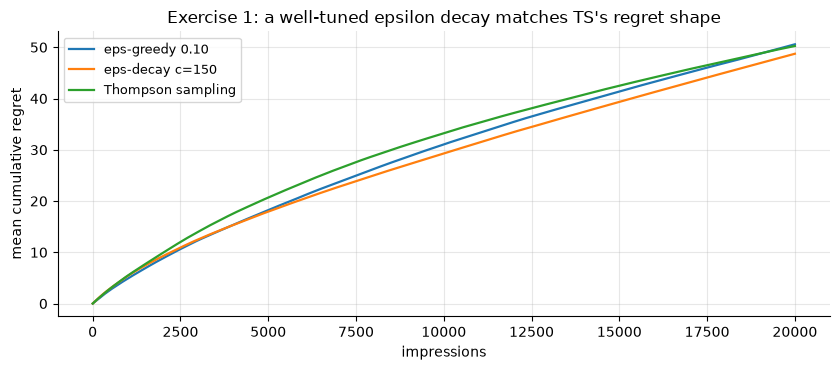


Reading: the decay schedule fixes the *tail* - exploration cost ~ c log T, so the curve
bends like TS's, and with c=150 it even edges TS's mean at this horizon. The catch is
that c is doing the work: epsilon_t is a clock, not a belief. The right c depends on the
unknown gaps - too low and it locks in like greedy, too high and it dawdles - and this
c was tuned with knowledge of the truth. TS gets the same log-shape with no tuning
because its exploration is driven by posterior uncertainty, and unlike the clock it
re-opens exploration if the world surprises it.


In [22]:
# --- Solution to Exercise 1 ---
def make_eps_decay(c):
    def policy(s, f, t, gen):
        eps = min(1.0, c / (t + 1))
        return make_eps_greedy(eps)(s, f, t, gen)
    return policy


ex1 = {
    "eps-greedy 0.10": race["eps-greedy 0.10"],
    "eps-decay c=150": simulate(make_eps_decay(150), TRUE_CTR, T_RACE, N_RUNS, seed=95),
    "Thompson sampling": race["Thompson sampling"],
}
print(pd.Series({n: r["regret"][-1].mean() for n, r in ex1.items()},
                name="mean final regret").round(1).to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for nme, res in ex1.items():
    ax.plot(res["cps"], res["regret"].mean(axis=1), lw=1.6, label=nme)
ax.set_title("Exercise 1: a well-tuned epsilon decay matches TS's regret shape")
ax.set_xlabel("impressions")
ax.set_ylabel("mean cumulative regret")
ax.legend(fontsize=9)
plt.show()
print("""
Reading: the decay schedule fixes the *tail* - exploration cost ~ c log T, so the curve
bends like TS's, and with c=150 it even edges TS's mean at this horizon. The catch is
that c is doing the work: epsilon_t is a clock, not a belief. The right c depends on the
unknown gaps - too low and it locks in like greedy, too high and it dawdles - and this
c was tuned with knowledge of the truth. TS gets the same log-shape with no tuning
because its exploration is driven by posterior uncertainty, and unlike the clock it
re-opens exploration if the world surprises it.""")

Gaussian TS        251.4
eps-greedy 0.10    289.7


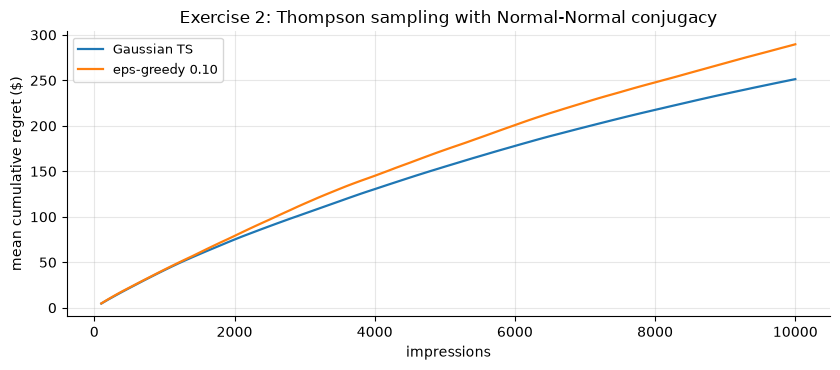


Reading: same recipe, different likelihood - keep a conjugate posterior per arm, sample
once, act on the sample. With sigma=2 against gaps of 0.05-0.10 the signal-to-noise per
pull is tiny, so both policies pay heavily early; TS still wins because its exploration
concentrates on the 0.55-vs-0.60 contest instead of revisiting the clearly-worse arm
forever. Any reward model with a samplable posterior (logistic, hierarchical, GP) slots
into the same act-on-one-draw loop.


In [23]:
# --- Solution to Exercise 2 ---
# Normal-Normal: prior N(m0, v0), known reward variance s2. After n pulls with mean xbar:
#   posterior precision 1/v = 1/v0 + n/s2 ; posterior mean m = v * (m0/v0 + n*xbar/s2).
MU_G, SIG_G = np.array([0.55, 0.60, 0.50]), 2.0
M0, V0 = 0.5, 1.0
T_G, R_G = 10_000, 150


def gaussian_race(kind, seed):
    gen = child_rng(seed)
    n, k = R_G, len(MU_G)
    cnt = np.zeros((n, k))
    tot = np.zeros((n, k))            # sum of rewards
    gaps = MU_G.max() - MU_G
    cum = np.zeros(n)
    hist = []
    rows = np.arange(n)
    for t in range(T_G):
        post_prec = 1 / V0 + cnt / SIG_G ** 2
        post_mean = (M0 / V0 + tot / SIG_G ** 2) / post_prec
        if kind == "ts":
            a = (post_mean + gen.normal(size=(n, k)) / np.sqrt(post_prec)).argmax(axis=1)
        else:
            a = (post_mean + gen.uniform(0, 1e-9, (n, k))).argmax(axis=1)
            explore = gen.random(n) < 0.10
            if explore.any():
                a[explore] = gen.integers(0, k, int(explore.sum()))
        r = gen.normal(MU_G[a], SIG_G)
        cnt[rows, a] += 1
        tot[rows, a] += r
        cum += gaps[a]
        if (t + 1) % 100 == 0:
            hist.append(cum.mean())
    return np.array(hist), cum


gauss = {"Gaussian TS": gaussian_race("ts", 96), "eps-greedy 0.10": gaussian_race("eps", 97)}
print(pd.Series({n: c.mean() for n, (h, c) in gauss.items()},
                name="mean final regret ($)").round(1).to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for nme, (h, c) in gauss.items():
    ax.plot(np.arange(100, T_G + 1, 100), h, lw=1.6, label=nme)
ax.set_title("Exercise 2: Thompson sampling with Normal-Normal conjugacy")
ax.set_xlabel("impressions")
ax.set_ylabel("mean cumulative regret ($)")
ax.legend(fontsize=9)
plt.show()
print("""
Reading: same recipe, different likelihood - keep a conjugate posterior per arm, sample
once, act on the sample. With sigma=2 against gaps of 0.05-0.10 the signal-to-noise per
pull is tiny, so both policies pay heavily early; TS still wins because its exploration
concentrates on the 0.55-vs-0.60 contest instead of revisiting the clearly-worse arm
forever. Any reward model with a samplable posterior (logistic, hierarchical, GP) slots
into the same act-on-one-draw loop.""")

In [24]:
# --- Solution to Exercise 3 ---
def ts_with_holdout(true_p, T, n_runs, frac, seed):
    true_p = np.asarray(true_p, float)
    n, k = n_runs, len(true_p)
    gen = child_rng(seed)
    s = np.zeros((n, k))
    f = np.zeros((n, k))
    hs = np.zeros((n, k))            # holdout successes / pulls
    hn = np.zeros((n, k))
    gaps = true_p.max() - true_p
    cum = np.zeros(n)
    rows = np.arange(n)
    for t in range(T):
        a = np.argmax(gen.beta(s + 1, f + 1), axis=1)
        hold = gen.random(n) < frac
        if hold.any():
            a[hold] = gen.integers(0, k, int(hold.sum()))
        r = gen.random(n) < true_p[a]
        s[rows, a] += r                       # the bandit learns from ALL traffic
        f[rows, a] += ~r
        hs[rows[hold], a[hold]] += r[hold]    # estimation uses holdout only
        hn[rows[hold], a[hold]] += 1
        cum += gaps[a]
    return s / np.maximum(s + f, 1), hs / np.maximum(hn, 1), cum


pooled_hat, hold_hat, ho_reg = ts_with_holdout(TRUE_CTR, T_RACE, 400, frac=0.10, seed=98)
ex3 = pd.DataFrame({
    "true p": TRUE_CTR,
    "pooled bias (pp)": 100 * (pooled_hat.mean(axis=0) - TRUE_CTR),
    "holdout bias (pp)": 100 * (hold_hat.mean(axis=0) - TRUE_CTR),
    "holdout bias SE (pp)": 100 * hold_hat.std(axis=0) / np.sqrt(len(hold_hat)),
}, index=arms.index)
print(ex3.round(3).to_string())

pure_ts = race["Thompson sampling"]["regret"][-1].mean()
unif = race["uniform A/B/n"]["regret"][-1].mean()
print(f"\nregret: pure TS {pure_ts:.1f} | TS + 10% holdout {ho_reg.mean():.1f} "
      f"| predicted {pure_ts + 0.10 * (unif - pure_ts):.1f} (= TS + 10% of the uniform-TS gap)")
print("""
Reading: the holdout impressions are assigned by a coin flip that ignores the data, so
their arm means are unbiased by construction - the pooled means keep the adaptive bias.
The regret cost lands close to (slightly under) the back-of-envelope prediction of
frac x (uniform regret - bandit regret): a holdout impression pays the uniform regret
rate instead of TS's - 'slightly under' because the bandit also learns from the holdout
traffic. That formula is the 'price sheet' for honest measurement, a number you can put
in front of a PM when negotiating the holdout size.""")

    true p  pooled bias (pp)  holdout bias (pp)  holdout bias SE (pp)
H1   0.032            -0.189              0.012                 0.041
H2   0.041            -0.044             -0.074                 0.044
H3   0.037            -0.154             -0.044                 0.041
H4   0.028            -0.108              0.024                 0.036

regret: pure TS 50.2 | TS + 10% holdout 55.6 | predicted 58.2 (= TS + 10% of the uniform-TS gap)

Reading: the holdout impressions are assigned by a coin flip that ignores the data, so
their arm means are unbiased by construction - the pooled means keep the adaptive bias.
The regret cost lands close to (slightly under) the back-of-envelope prediction of
frac x (uniform regret - bandit regret): a holdout impression pays the uniform regret
rate instead of TS's - 'slightly under' because the bandit also learns from the holdout
traffic. That formula is the 'price sheet' for honest measurement, a number you can put
in front of a PM when negotiati